# 菲涅尔公式

In [68]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.family": "sans-serif", #采用无衬线字体
    "font.sans-serif": ["Microsoft YaHei", 'SimHei'], #依次尝试设置字体为微软雅黑、黑体
    "axes.unicode_minus": False, # 设置正确显示负号
    "font.size": 12, #字体大小
    "figure.figsize": (8, 6), #图像尺寸
    "figure.dpi": 150, #图像显示清晰度
    "figure.facecolor": "white", #画布底色
    "figure.constrained_layout.use": True, #自动收紧边距
    "axes.grid": True, #显示网格
    "grid.alpha": 0.3, #网格透明度
    "axes.axisbelow": True, #网格线压在数据层下面
    "savefig.dpi": 200, #保存图像分辨率
    "savefig.bbox": "tight", #保存图像自动裁剪白边
    "savefig.format": "png", #保存图像格式
})

## 函数定义

菲涅尔公式有
$$
\begin{dcases}
	\tilde{E}'_{1p}=\frac{n_2\cos\theta_1-n_1\cos\theta_2}{n_2\cos\theta_1+n_1\cos\theta_2}\tilde{E}_{1p}\qquad\tilde{E}'_{1s}=\frac{n_1\cos\theta_1-n_2\cos\theta_2}{n_1\cos\theta_1+n_2\cos\theta_2}\tilde{E}_{1s} \\
	\\
	\tilde{E}_{2p}=\frac{2n_1\cos\theta_1}{n_2\cos\theta_1+n_1\cos\theta_2}\tilde{E}_{1p}\qquad\tilde{E}_{2s}=\frac{2n_1\cos\theta_1}{n_1\cos\theta_1+n_2\cos\theta_2}\tilde{E}_{1s} \\
\end{dcases}
$$
记 $\alpha=n_1/n_2$，$\theta$ 为入射角，则复振幅反射率和透射率可以写为
$$
\begin{dcases}
    \tilde{r}_p=r_p\mathrm{e}^{\mathrm{i}\delta'_p}=\frac{\tilde{E}'_{1p}}{\tilde{E}_{1p}}=\frac{\cos\theta-\alpha\sqrt{1-\alpha^2\sin^2\theta}}{\cos\theta+\alpha\sqrt{1-\alpha^2\sin^2\theta}}, &\quad\tilde{r}_s=r_s\mathrm{e}^{\mathrm{i}\delta'_s}=\frac{\tilde{E}'_{1s}}{\tilde{E}_{1s}}=\frac{\alpha\cos\theta-\sqrt{1-\alpha^2\sin^2\theta}}{\alpha\cos\theta+\sqrt{1-\alpha^2\sin^2\theta}} \\
    \\
    \tilde{t}_p=t_p\mathrm{e}^{\mathrm{i}\delta_p}=\frac{\tilde{E}_{2p}}{\tilde{E}_{1p}}=\frac{2\alpha\cos\theta}{\cos\theta+\alpha\sqrt{1-\alpha^2\sin^2\theta}}, &\quad\tilde{t}_s=t_s\mathrm{e}^{\mathrm{i}\delta_s}=\frac{\tilde{E}_{2s}}{\tilde{E}_{1s}}=\frac{2\alpha\cos\theta}{\alpha\cos\theta+\sqrt{1-\alpha^2\sin^2\theta}}
\end{dcases}
$$
全反射角和布鲁斯特角分别满足（当然只有在 $\alpha>1$ 时才有全反射）
$$
\sin\theta_\text{c}=\frac{1}{\alpha}=\frac{n_2}{n_1}, \quad\tan\theta_\text{b}=\frac{1}{\alpha}=\frac{n_2}{n_1}
$$

### p光复振幅反射率 $\tilde{r}_p$

In [69]:
def rp(alpha, theta):
    """|r_p|"""
    if alpha < 1:
        theta_b = np.arctan(1/alpha)

        theta1 = theta[theta < theta_b]
        C1 = np.cos(theta1); S1 = np.sin(theta1)
        rp1 = (C1 - alpha*np.sqrt(1 - alpha**2 * S1**2)) / (C1 + alpha*np.sqrt(1 - alpha**2 * S1**2))

        theta2 = theta[theta >= theta_b]
        C2 = np.cos(theta2); S2 = np.sin(theta2)
        rp2 = - (C2 - alpha*np.sqrt(1 - alpha**2 * S2**2)) / (C2 + alpha*np.sqrt(1 - alpha**2 * S2**2))

        rp = np.concatenate((rp1, rp2))

    elif alpha > 1:
        theta_b = np.arctan(1/alpha)
        theta_c = np.arcsin(1/alpha)

        theta1 = theta[theta < theta_b]
        C1 = np.cos(theta1); S1 = np.sin(theta1)
        rp1 = - (C1 - alpha*np.sqrt(1 - alpha**2 * S1**2)) / (C1 + alpha*np.sqrt(1 - alpha**2 * S1**2))

        theta2 = theta[theta < theta_c]
        theta2 = theta2[theta_b <= theta2]
        C2 = np.cos(theta2); S2 = np.sin(theta2)
        rp2 = (C2 - alpha*np.sqrt(1 - alpha**2 * S2**2)) / (C2 + alpha*np.sqrt(1 - alpha**2 * S2**2))

        theta3 = theta[theta >= theta_c]
        rp3 = np.ones_like(theta3)

        rp = np.concatenate((rp1, rp2, rp3))

    else:
        raise ValueError("alpha = 1")

    return rp

def delta_rp(alpha, theta):
    """arg(r_p)"""
    if alpha < 1:
        theta_b = np.arctan(1/alpha)

        theta1 = theta[theta < theta_b]
        delta_rp1 = np.zeros_like(theta1)

        theta2 = theta[theta >= theta_b]
        delta_rp2 = np.pi * np.ones_like(theta2)

        delta_rp = np.concatenate((delta_rp1, delta_rp2))

    elif alpha > 1:
        theta_b = np.arctan(1/alpha)
        theta_c = np.arcsin(1/alpha)

        theta1 = theta[theta < theta_b]
        delta_rp1 = np.pi * np.ones_like(theta1)

        theta2 = theta[theta < theta_c]
        theta2 = theta2[theta_b <= theta2]
        delta_rp2 = np.zeros_like(theta2)

        theta3 = theta[theta >= theta_c]
        C3 = np.cos(theta3); S3 = np.sin(theta3)
        delta_rp3 = -2 * np.arctan(alpha * np.sqrt(alpha**2 * S3**2 - 1) / C3)

        delta_rp = np.concatenate((delta_rp1, delta_rp2, delta_rp3))

    else:
        raise ValueError("alpha = 1")

    return delta_rp


### s光复振幅反射率 $\tilde{r}_s$

In [70]:
def rs(alpha, theta):
    """|r_s|"""
    if alpha < 1:
        C = np.cos(theta); S = np.sin(theta)
        rs = - (alpha*C - np.sqrt(1 - alpha**2 * S**2)) / (alpha*C + np.sqrt(1 - alpha**2 * S**2))

    elif alpha > 1:
        theta_c = np.arcsin(1/alpha)

        theta1 = theta[theta < theta_c]
        C1 = np.cos(theta1); S1 = np.sin(theta1)
        rs1 = (alpha*C1 - np.sqrt(1 - alpha**2 * S1**2)) / (alpha*C1 + np.sqrt(1 - alpha**2 * S1**2))

        theta2 = theta[theta >= theta_c]
        rs2 = np.ones_like(theta2)

        rs = np.concatenate((rs1, rs2))

    else:
        raise ValueError("alpha = 1")

    return rs

def delta_rs(alpha, theta):
    """arg(r_s)"""
    if alpha < 1:
        delta_rs = np.pi * np.ones_like(theta)

    elif alpha > 1:
        theta_c = np.arcsin(1/alpha)

        theta1 = theta[theta < theta_c]
        delta_rs1 = np.zeros_like(theta1)

        theta2 = theta[theta >= theta_c]
        C2 = np.cos(theta2); S2 = np.sin(theta2)
        delta_rs2 = -2 * np.arctan(np.sqrt(alpha**2 * S2**2 - 1) / (alpha*C2))

        delta_rs = np.concatenate((delta_rs1, delta_rs2))

    else:
        raise ValueError("alpha = 1")

    return delta_rs


### p光复振幅透射率 $\tilde{t}_p$

In [71]:
def tp(alpha, theta):
    """|t_p|"""
    if alpha < 1:
        C = np.cos(theta); S = np.sin(theta)
        tp = 2*alpha*C / (C + alpha*np.sqrt(1 - alpha**2 * S**2))

    elif alpha > 1:
        theta_c = np.arcsin(1/alpha)

        theta1 = theta[theta < theta_c]
        C1 = np.cos(theta1); S1 = np.sin(theta1)
        tp1 = 2*alpha*C1 / (C1 + alpha*np.sqrt(1 - alpha**2 * S1**2))

        theta2 = theta[theta >= theta_c]
        C2 = np.cos(theta2); S2 = np.sin(theta2)
        tp2 = 2*alpha*C2 / (np.sqrt(C2**2 + alpha**4 * S2**2 - alpha**2))

        tp = np.concatenate((tp1, tp2))

    else:
        raise ValueError("alpha = 1")

    return tp

def delta_tp(alpha, theta):
    """arg(t_p)"""
    if alpha < 1:
        delta_tp = np.zeros_like(theta)

    elif alpha > 1:
        theta_c = np.arcsin(1/alpha)

        theta1 = theta[theta < theta_c]
        delta_tp1 = np.zeros_like(theta1)

        theta2 = theta[theta >= theta_c]
        C2 = np.cos(theta2); S2 = np.sin(theta2)
        delta_tp2 = -np.arctan(alpha * np.sqrt(alpha**2 * S2**2 - 1) / C2)

        delta_tp = np.concatenate((delta_tp1, delta_tp2))

    else:
        raise ValueError("alpha = 1")

    return delta_tp

### s光复振幅透射率 $\tilde{t}_s$

In [72]:
def ts(alpha, theta):
    """|t_s|"""
    if alpha < 1:
        C = np.cos(theta); S = np.sin(theta)
        ts = 2*alpha*C / (alpha*C + np.sqrt(1 - alpha**2 * S**2))

    elif alpha > 1:
        theta_c = np.arcsin(1/alpha)

        theta1 = theta[theta < theta_c]
        C1 = np.cos(theta1); S1 = np.sin(theta1)
        ts1 = 2*alpha*C1 / (alpha*C1 + np.sqrt(1 - alpha**2 * S1**2))

        theta2 = theta[theta >= theta_c]
        C2 = np.cos(theta2); S2 = np.sin(theta2)
        ts2 = 2*alpha*C2 / (np.sqrt(alpha**2 - 1))

        ts = np.concatenate((ts1, ts2))

    else:
        raise ValueError("alpha = 1")

    return ts

def delta_ts(alpha, theta):
    """arg(t_s)"""
    if alpha < 1:
        delta_ts = np.zeros_like(theta)

    elif alpha > 1:
        theta_c = np.arcsin(1/alpha)

        theta1 = theta[theta < theta_c]
        delta_ts1 = np.zeros_like(theta1)

        theta2 = theta[theta >= theta_c]
        C2 = np.cos(theta2); S2 = np.sin(theta2)
        delta_ts2 = -np.arctan(np.sqrt(alpha**2 * S2**2 - 1) / (alpha * C2))

        delta_ts = np.concatenate((delta_ts1, delta_ts2))

    else:
        raise ValueError("alpha = 1")

    return delta_ts

# 可视化

In [73]:
theta_arr = np.linspace(0, np.pi/2-1e-4, 1000)
C = np.cos(theta_arr); S = np.sin(theta_arr)
theta_show = np.rad2deg(theta_arr)

## $\alpha < 1$ 的情况

In [74]:
alpha1 = 0.667
theta_b1 = np.arctan(1/alpha1)
# 复振幅反射率和折射率
rp1 = rp(alpha1, theta_arr); delta_rp1 = delta_rp(alpha1, theta_arr); arg_rp1 = np.rad2deg(delta_rp1)
rs1 = rs(alpha1, theta_arr); delta_rs1 = delta_rs(alpha1, theta_arr); arg_rs1 = np.rad2deg(delta_rs1)
tp1 = tp(alpha1, theta_arr); delta_tp1 = delta_tp(alpha1, theta_arr); arg_tp1 = np.rad2deg(delta_tp1)
ts1 = ts(alpha1, theta_arr); delta_ts1 = delta_ts(alpha1, theta_arr); arg_ts1 = np.rad2deg(delta_ts1)
# 光功率反射率和透射率
Rp1 = rp1**2
Rs1 = rs1**2
Tp1 = np.sqrt(1 - alpha1**2 * S**2) / (alpha1 * C) * tp1**2
Ts1 = np.sqrt(1 - alpha1**2 * S**2) / (alpha1 * C) * ts1**2

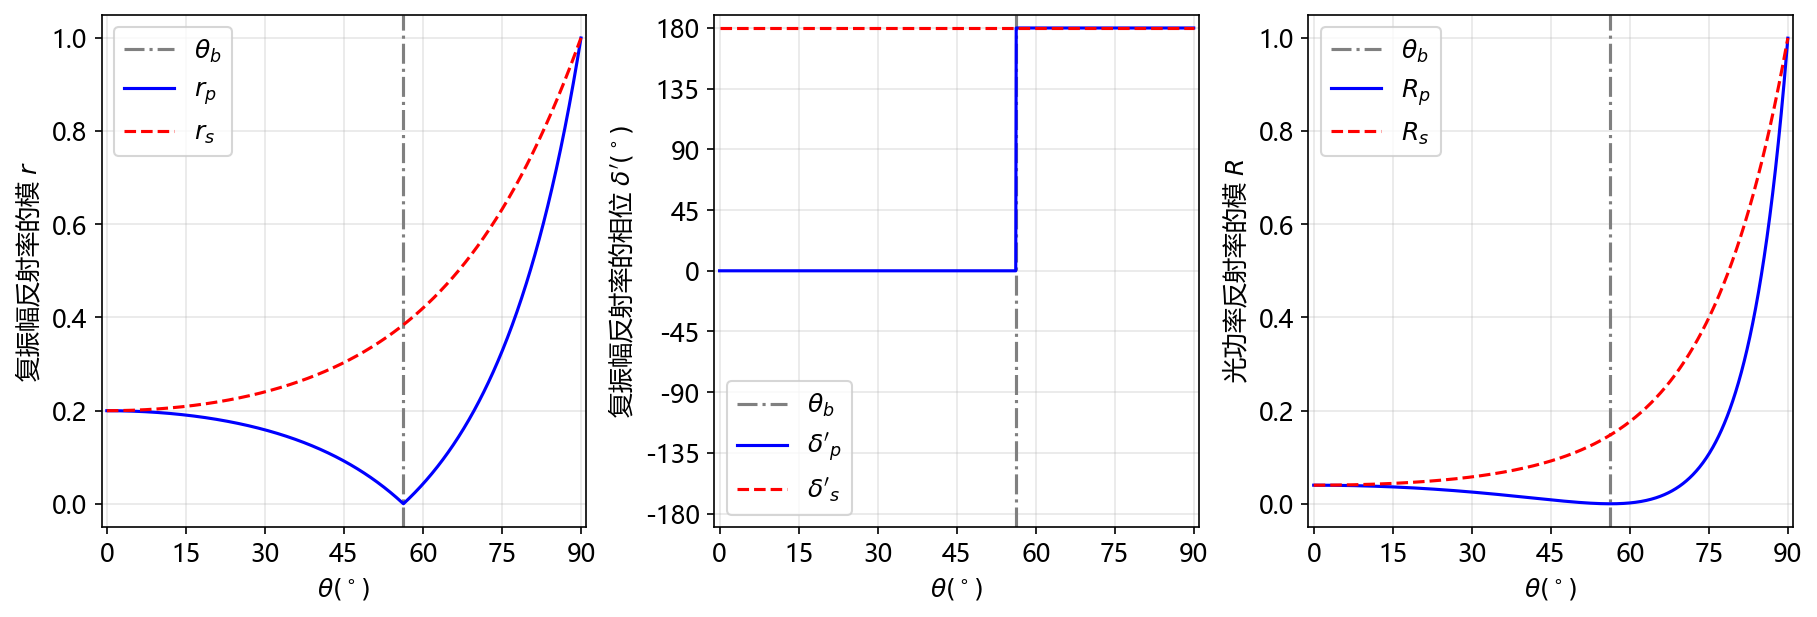

In [75]:
fig1, ax1 = plt.subplots(1, 3, figsize=(12, 4))
ax1[0].axvline(np.rad2deg(theta_b1), color='gray', linestyle='-.', label=r"$\theta_b$")
ax1[0].plot(theta_show, rp1, 'b-', label=r'$r_p$')
ax1[0].plot(theta_show, rs1, 'r--', label=r'$r_s$')
ax1[0].set_xlim([-1, 91])
ax1[0].set_ylim([-0.05, 1.05])
ax1[0].set_xticks(np.arange(0, 91, 15))
ax1[0].set_yticks(np.arange(0, 1.1, 0.2))
ax1[0].set_xlabel(r"$\theta (^\circ)$")
ax1[0].set_ylabel(r"复振幅反射率的模 $r$")
ax1[0].legend()

ax1[1].axvline(np.rad2deg(theta_b1), color='gray', linestyle='-.', label=r"$\theta_b$")
ax1[1].plot(theta_show, arg_rp1, 'b-', label=r"$\delta'_p$")
ax1[1].plot(theta_show, arg_rs1, 'r--', label=r"$\delta'_s$")
ax1[1].set_xlim([-1, 91])
ax1[1].set_ylim([-190, 190])
ax1[1].set_xticks(np.arange(0, 91, 15))
ax1[1].set_yticks(np.arange(-180, 181, 45))
ax1[1].set_xlabel(r"$\theta (^\circ)$")
ax1[1].set_ylabel(r"复振幅反射率的相位 $\delta' (^\circ)$")
ax1[1].legend()

ax1[2].axvline(np.rad2deg(theta_b1), color='gray', linestyle='-.', label=r"$\theta_b$")
ax1[2].plot(theta_show, Rp1, 'b-', label=r'$R_p$')
ax1[2].plot(theta_show, Rs1, 'r--', label=r'$R_s$')
ax1[2].set_xlim([-1, 91])
ax1[2].set_ylim([-0.05, 1.05])
ax1[2].set_xticks(np.arange(0, 91, 15))
ax1[2].set_yticks(np.arange(0, 1.1, 0.2))
ax1[2].set_xlabel(r"$\theta (^\circ)$")
ax1[2].set_ylabel(r"光功率反射率的模 $R$")
ax1[2].legend()

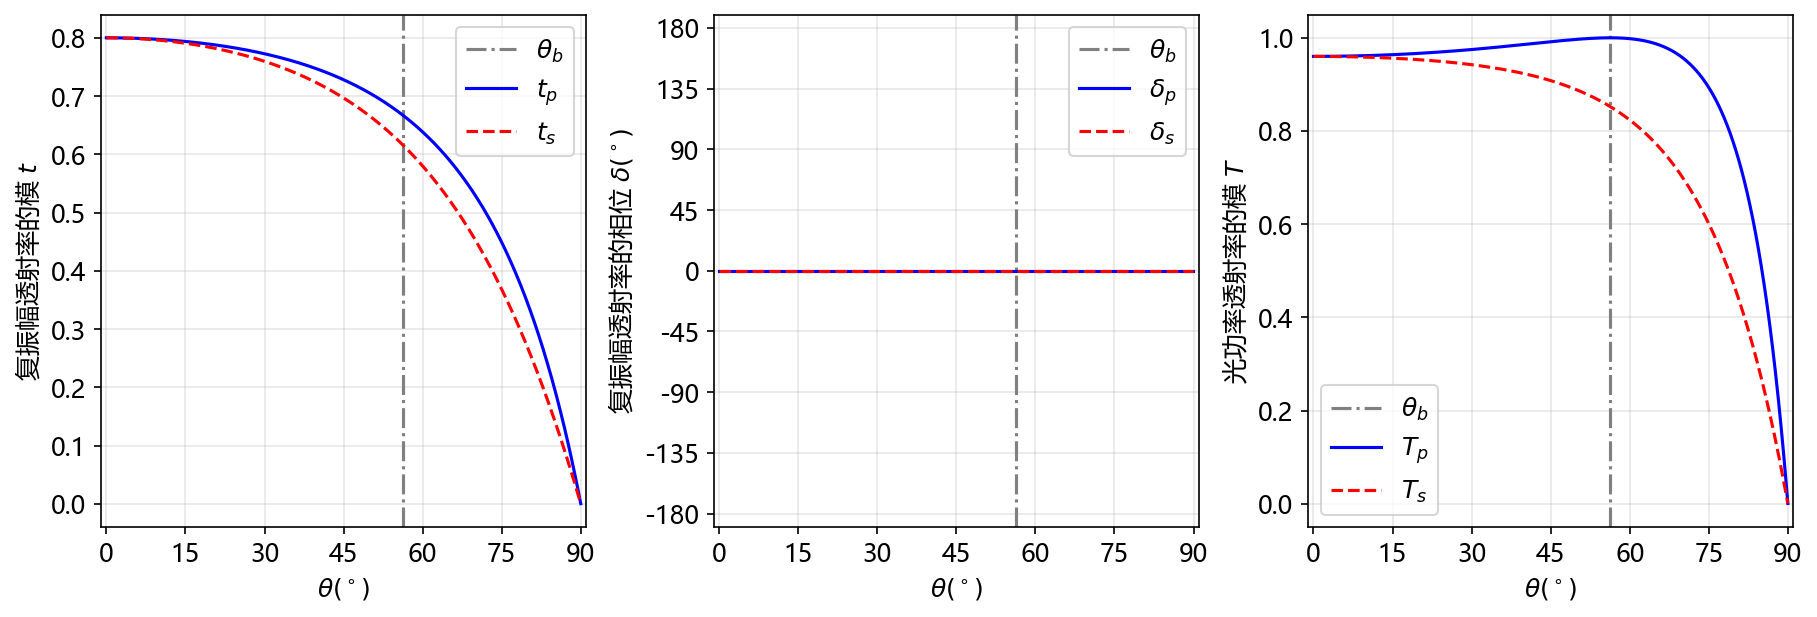

In [76]:
fig2, ax2 = plt.subplots(1, 3, figsize=(12, 4))
ax2[0].axvline(np.rad2deg(theta_b1), color='gray', linestyle='-.', label=r"$\theta_b$")
ax2[0].plot(theta_show, tp1, 'b-', label=r'$t_p$')
ax2[0].plot(theta_show, ts1, 'r--', label=r'$t_s$')
ax2[0].set_xlim([-1, 91])
# ax2[0].set_ylim([-0.05, 1.05])
ax2[0].set_xticks(np.arange(0, 91, 15))
# ax2[0].set_yticks(np.arange(0, 1.1, 0.2))
ax2[0].set_xlabel(r"$\theta (^\circ)$")
ax2[0].set_ylabel(r"复振幅透射率的模 $t$")
ax2[0].legend()

ax2[1].axvline(np.rad2deg(theta_b1), color='gray', linestyle='-.', label=r"$\theta_b$")
ax2[1].plot(theta_show, arg_tp1, 'b-', label=r"$\delta_p$")
ax2[1].plot(theta_show, arg_ts1, 'r--', label=r"$\delta_s$")
ax2[1].set_xlim([-1, 91])
ax2[1].set_ylim([-190, 190])
ax2[1].set_xticks(np.arange(0, 91, 15))
ax2[1].set_yticks(np.arange(-180, 181, 45))
ax2[1].set_xlabel(r"$\theta (^\circ)$")
ax2[1].set_ylabel(r"复振幅透射率的相位 $\delta (^\circ)$")
ax2[1].legend()

ax2[2].axvline(np.rad2deg(theta_b1), color='gray', linestyle='-.', label=r"$\theta_b$")
ax2[2].plot(theta_show, Tp1, 'b-', label=r'$T_p$')
ax2[2].plot(theta_show, Ts1, 'r--', label=r'$T_s$')
ax2[2].set_xlim([-1, 91])
ax2[2].set_ylim([-0.05, 1.05])
ax2[2].set_xticks(np.arange(0, 91, 15))
ax2[2].set_yticks(np.arange(0, 1.1, 0.2))
ax2[2].set_xlabel(r"$\theta (^\circ)$")
ax2[2].set_ylabel(r"光功率透射率的模 $T$")
ax2[2].legend()

## $\alpha > 1$ 的情况

In [80]:
alpha2 = 1.5
theta_b2 = np.arctan(1/alpha2); theta_c2 = np.arcsin(1/alpha2)
# 复振幅反射率和折射率
rp2 = rp(alpha2, theta_arr); delta_rp2 = delta_rp(alpha2, theta_arr); arg_rp2 = np.rad2deg(delta_rp2)
rs2 = rs(alpha2, theta_arr); delta_rs2 = delta_rs(alpha2, theta_arr); arg_rs2 = np.rad2deg(delta_rs2)
tp2 = tp(alpha2, theta_arr); delta_tp2 = delta_tp(alpha2, theta_arr); arg_tp2 = np.rad2deg(delta_tp2)
ts2 = ts(alpha2, theta_arr); delta_ts2 = delta_ts(alpha2, theta_arr); arg_ts2 = np.rad2deg(delta_ts2)
# 光功率反射率和透射率
Rp2 = rp2**2
Rs2 = rs2**2
# Tp2 = np.sqrt(1 - alpha2**2 * S**2) / (alpha2 * C) * tp2**2
# Ts2 = np.sqrt(1 - alpha2**2 * S**2) / (alpha2 * C) * ts2**2
with np.errstate(invalid="ignore", divide="ignore"):
    factor2 = np.sqrt(1 - alpha2**2 * S**2) / (alpha2 * C)
Tp2 = factor2 * tp2**2
Ts2 = factor2 * ts2**2

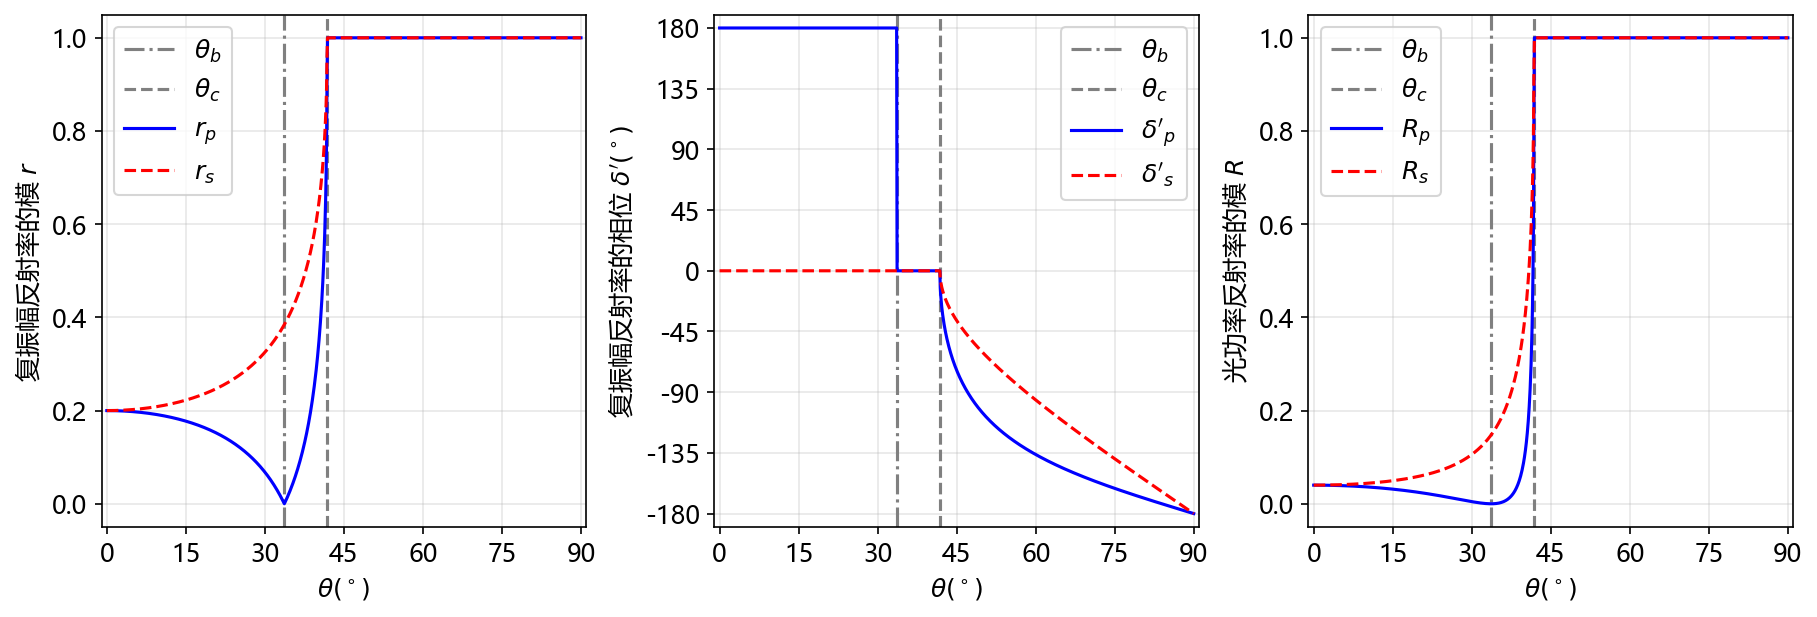

In [81]:
fig3, ax3 = plt.subplots(1, 3, figsize=(12, 4))
ax3[0].axvline(np.rad2deg(theta_b2), color='gray', linestyle='-.', label=r"$\theta_b$")
ax3[0].axvline(np.rad2deg(theta_c2), color='gray', linestyle='--', label=r"$\theta_c$")
ax3[0].plot(theta_show, rp2, 'b-', label=r'$r_p$')
ax3[0].plot(theta_show, rs2, 'r--', label=r'$r_s$')
ax3[0].set_xlim([-1, 91])
ax3[0].set_ylim([-0.05, 1.05])
ax3[0].set_xticks(np.arange(0, 91, 15))
ax3[0].set_yticks(np.arange(0, 1.1, 0.2))
ax3[0].set_xlabel(r"$\theta (^\circ)$")
ax3[0].set_ylabel(r"复振幅反射率的模 $r$")
ax3[0].legend()

ax3[1].axvline(np.rad2deg(theta_b2), color='gray', linestyle='-.', label=r"$\theta_b$")
ax3[1].axvline(np.rad2deg(theta_c2), color='gray', linestyle='--', label=r"$\theta_c$")
ax3[1].plot(theta_show, arg_rp2, 'b-', label=r"$\delta'_p$")
ax3[1].plot(theta_show, arg_rs2, 'r--', label=r"$\delta'_s$")
ax3[1].set_xlim([-1, 91])
ax3[1].set_ylim([-190, 190])
ax3[1].set_xticks(np.arange(0, 91, 15))
ax3[1].set_yticks(np.arange(-180, 181, 45))
ax3[1].set_xlabel(r"$\theta (^\circ)$")
ax3[1].set_ylabel(r"复振幅反射率的相位 $\delta' (^\circ)$")
ax3[1].legend()

ax3[2].axvline(np.rad2deg(theta_b2), color='gray', linestyle='-.', label=r"$\theta_b$")
ax3[2].axvline(np.rad2deg(theta_c2), color='gray', linestyle='--', label=r"$\theta_c$")
ax3[2].plot(theta_show, Rp2, 'b-', label=r'$R_p$')
ax3[2].plot(theta_show, Rs2, 'r--', label=r'$R_s$')
ax3[2].set_xlim([-1, 91])
ax3[2].set_ylim([-0.05, 1.05])
ax3[2].set_xticks(np.arange(0, 91, 15))
ax3[2].set_yticks(np.arange(0, 1.1, 0.2))
ax3[2].set_xlabel(r"$\theta (^\circ)$")
ax3[2].set_ylabel(r"光功率反射率的模 $R$")
ax3[2].legend()

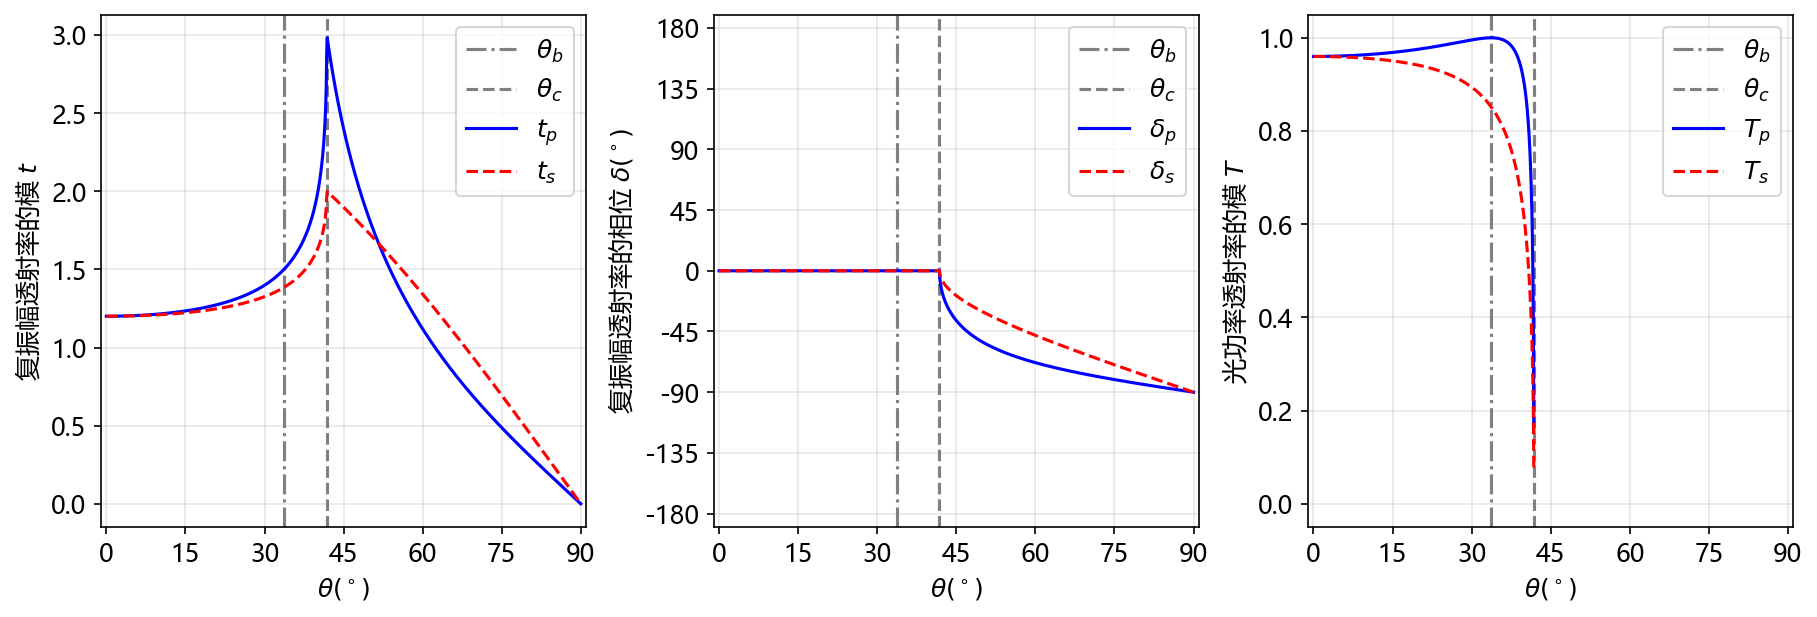

In [83]:
fig4, ax4 = plt.subplots(1, 3, figsize=(12, 4))
ax4[0].axvline(np.rad2deg(theta_b2), color='gray', linestyle='-.', label=r"$\theta_b$")
ax4[0].axvline(np.rad2deg(theta_c2), color='gray', linestyle='--', label=r"$\theta_c$")
ax4[0].plot(theta_show, tp2, 'b-', label=r'$t_p$')
ax4[0].plot(theta_show, ts2, 'r--', label=r'$t_s$')
ax4[0].set_xlim([-1, 91])
# ax4[0].set_ylim([-0.05, 1.05])
ax4[0].set_xticks(np.arange(0, 91, 15))
# ax4[0].set_yticks(np.arange(0, 1.1, 0.2))
ax4[0].set_xlabel(r"$\theta (^\circ)$")
ax4[0].set_ylabel(r"复振幅透射率的模 $t$")
ax4[0].legend()

ax4[1].axvline(np.rad2deg(theta_b2), color='gray', linestyle='-.', label=r"$\theta_b$")
ax4[1].axvline(np.rad2deg(theta_c2), color='gray', linestyle='--', label=r"$\theta_c$")
ax4[1].plot(theta_show, arg_tp2, 'b-', label=r"$\delta_p$")
ax4[1].plot(theta_show, arg_ts2, 'r--', label=r"$\delta_s$")
ax4[1].set_xlim([-1, 91])
ax4[1].set_ylim([-190, 190])
ax4[1].set_xticks(np.arange(0, 91, 15))
ax4[1].set_yticks(np.arange(-180, 181, 45))
ax4[1].set_xlabel(r"$\theta (^\circ)$")
ax4[1].set_ylabel(r"复振幅透射率的相位 $\delta (^\circ)$")
ax4[1].legend()

ax4[2].axvline(np.rad2deg(theta_b2), color='gray', linestyle='-.', label=r"$\theta_b$")
ax4[2].axvline(np.rad2deg(theta_c2), color='gray', linestyle='--', label=r"$\theta_c$")
ax4[2].plot(theta_show, Tp2, 'b-', label=r'$T_p$')
ax4[2].plot(theta_show, Ts2, 'r--', label=r'$T_s$')
ax4[2].set_xlim([-1, 91])
ax4[2].set_ylim([-0.05, 1.05])
ax4[2].set_xticks(np.arange(0, 91, 15))
ax4[2].set_yticks(np.arange(0, 1.1, 0.2))
ax4[2].set_xlabel(r"$\theta (^\circ)$")
ax4[2].set_ylabel(r"光功率透射率的模 $T$")
ax4[2].legend()